Shape of the dataset: (383, 17)
   Age Gender Smoking Hx Smoking Hx Radiotherapy Thyroid Function  \
0   27      F      No         No              No        Euthyroid   
1   34      F      No        Yes              No        Euthyroid   
2   30      F      No         No              No        Euthyroid   
3   62      F      No         No              No        Euthyroid   
4   62      F      No         No              No        Euthyroid   

          Physical Examination Adenopathy       Pathology     Focality Risk  \
0   Single nodular goiter-left         No  Micropapillary    Uni-Focal  Low   
1          Multinodular goiter         No  Micropapillary    Uni-Focal  Low   
2  Single nodular goiter-right         No  Micropapillary    Uni-Focal  Low   
3  Single nodular goiter-right         No  Micropapillary    Uni-Focal  Low   
4          Multinodular goiter         No  Micropapillary  Multi-Focal  Low   

     T   N   M Stage       Response Recurred  
0  T1a  N0  M0     I  Indetermi

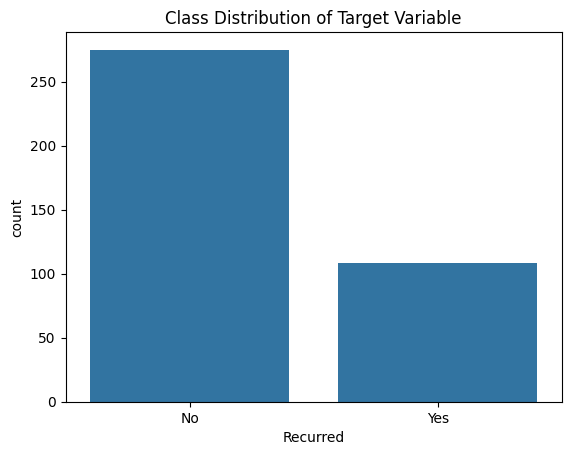

Using device: cpu
Epoch 1, Loss: 0.6740
Epoch 2, Loss: 0.5917
Epoch 3, Loss: 0.5158
Epoch 4, Loss: 0.4350
Epoch 5, Loss: 0.3266
Epoch 6, Loss: 0.2926
Epoch 7, Loss: 0.2786
Epoch 8, Loss: 0.2357
Epoch 9, Loss: 0.2292
Epoch 10, Loss: 0.2011
Epoch 11, Loss: 0.2514
Epoch 12, Loss: 0.1978
Epoch 13, Loss: 0.1956
Epoch 14, Loss: 0.2116
Epoch 15, Loss: 0.1831
Epoch 16, Loss: 0.1930
Epoch 17, Loss: 0.1737
Epoch 18, Loss: 0.1613
Epoch 19, Loss: 0.1635
Epoch 20, Loss: 0.1500
Accuracy 0.8636363636363636
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87        55
           1       0.88      0.84      0.86        55

    accuracy                           0.86       110
   macro avg       0.86      0.86      0.86       110
weighted avg       0.86      0.86      0.86       110



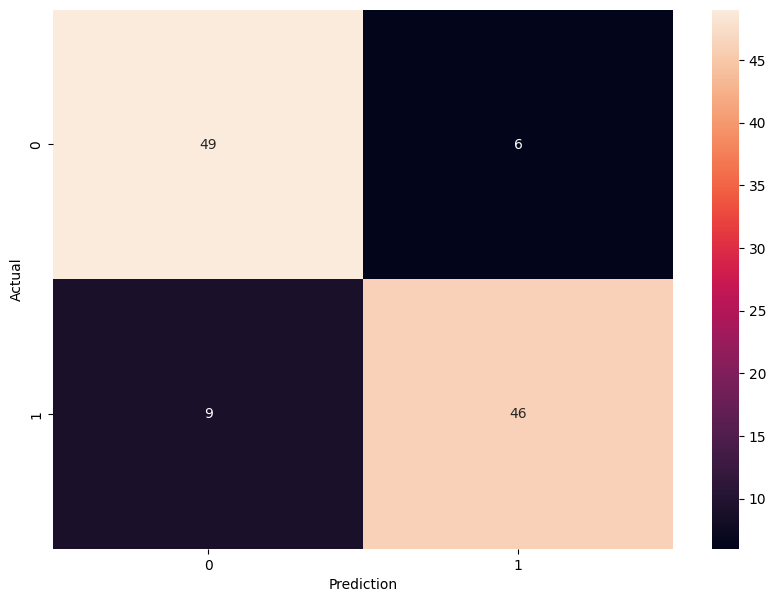

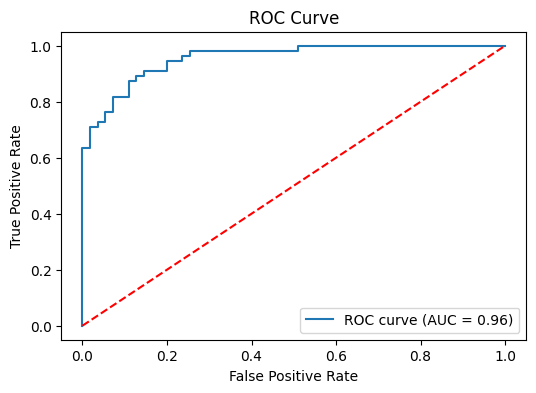

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_curve, auc
from imblearn.over_sampling import SMOTE

# Set random seed for reproducibility
def set_seed(seed_value=42):
    torch.manual_seed(seed_value)
    np.random.seed(seed_value)
    random.seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()

# Load the dataset
file_path = '../data/thyroid_diff.csv'  # Update file path as per your environment
data = pd.read_csv(file_path)

# Data preprocessing
# data = data.drop(['Focality', 'Stage', 'Risk', 'T', 'N', 'M'], axis='columns', errors='ignore')

if 'Recurred' not in data.columns:
    raise ValueError("The dataset does not contain a 'Recurred' column.")

print("Shape of the dataset:", data.shape)
print(data.head())

sns.countplot(x='Recurred', data=data)
plt.title('Class Distribution of Target Variable')
plt.show()

# Handle missing values
data = data.dropna()

# Encode categorical columns
categorical_columns = data.select_dtypes(include=['object']).columns
label_encoders = {col: LabelEncoder().fit(data[col]) for col in categorical_columns}
for col, le in label_encoders.items():
    data[col] = le.transform(data[col])

# Separate features and target
X = data.drop('Recurred', axis=1)
y = data['Recurred']

# Address class imbalance with SMOTE
X, y = SMOTE(random_state=42).fit_resample(X, y)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split data
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# GPU device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Convert data to tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_tensor.float(), y_train_tensor.long()), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor.float(), y_val_tensor.long()), batch_size=32)
test_loader = DataLoader(TensorDataset(X_test_tensor.float(), y_test_tensor.long()), batch_size=32)

# Define model
class ThyroidNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 2)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Initialize
model = ThyroidNet(X_train.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train function
def train(model, loader, val_loader, criterion, optimizer, epochs=20):
    for epoch in range(epochs):
        model.train()
        running_loss = 0
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"Epoch {epoch+1}, Loss: {running_loss / len(loader):.4f}")

# Train the model
train(model, train_loader, val_loader, criterion, optimizer)

# Evaluate
model.eval()
all_preds, all_trues = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_trues.extend(labels.cpu().numpy())

print("Accuracy {0}".format(accuracy_score(all_trues, all_preds)))

plt.figure(figsize=(10,7))
sns.heatmap(confusion_matrix(all_trues , all_preds) , annot=True , fmt='d')
plt.xlabel('Prediction')
plt.ylabel('Actual')

# Metrics
print("Classification Report:")
print(classification_report(all_trues, all_preds))

# ROC curve
probs = []
model.eval()
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        probs.append(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
probs = np.concatenate(probs)
fpr, tpr, thresholds = roc_curve(all_trues, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1],[0,1],'--', color='red')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title("ROC Curve")
plt.legend()
plt.show()
